## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

---

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
path = r"C:\Users\elham\OneDrive\Documents\IRONHACK\lab\EDA\amz_uk_price_prediction_dataset.csv"
data = pd.read_csv(path)

In [4]:
df=data.copy()

In [5]:
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
#datacleaning
df.columns = [col.lower().replace(" ", "_") for col in df.columns]

In [7]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isbestseller            bool
boughtinlastmonth      int64
category              object
dtype: object

In [8]:
df.shape

(2443651, 9)

In [9]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isbestseller         0
boughtinlastmonth    0
category             0
dtype: int64

### part 1.Frequency table 
Generate a frequency table for the product category

In [11]:
frequency_table = df['category'].value_counts()
frequency_table.reset_index()

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Alexa Built-In Devices,107
292,Motorbike Chassis,107
293,Plugs,107
294,Smart Home Security & Lighting,104


Which are the top 5 most listed product categories?

In [13]:
frequency_table = df['category'].value_counts().sort_values(ascending=False)[:5]
frequency_table.reset_index()

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


### part 1. Visualizations:
Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

In [15]:
category_counts = df['category'].value_counts().reset_index()
category_counts.columns = ['category', 'count']
top5_category= category_counts.head(5)

C:\Users\elham\AppData\Local\Temp\ipykernel_28932\98049195.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


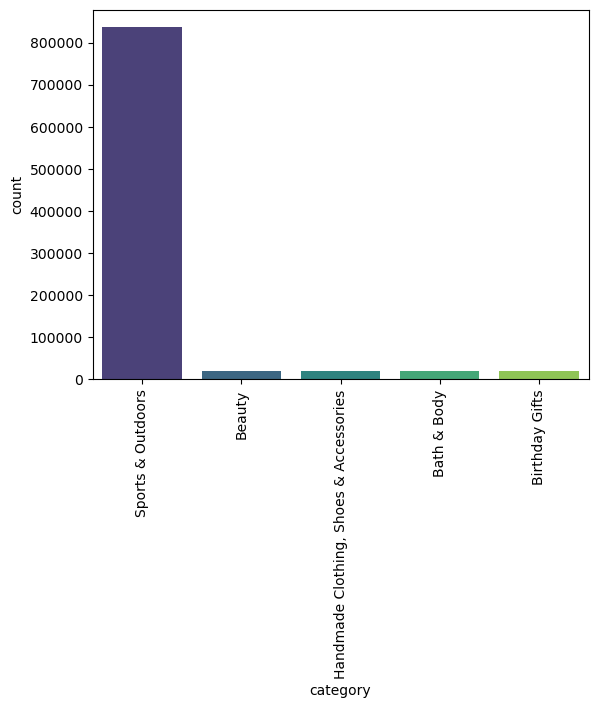

In [16]:
sns.barplot(
    x='category',
    y='count',
    data=top5_category,
    palette='viridis')
plt.xticks(rotation=90)
plt.show()

For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [18]:
proportion_table = df['category'].value_counts(normalize=True).reset_index()
proportion_table.columns= ['category', 'proportion']
top5_category_pro= proportion_table.head(5)
proportion_table

,category,proportion
0,Sports & Outdoors,0.342219
1,Beauty,0.007903
2,"Handmade Clothing, Shoes & Accessories",0.007869
3,Bath & Body,0.007813
4,Birthday Gifts,0.007766
...,...,...
291,Alexa Built-In Devices,0.000044
292,Motorbike Chassis,0.000044
293,Plugs,0.000044
294,Smart Home Security & Lighting,0.000043


In [19]:
proportion_table.dtypes

category       object
proportion    float64
dtype: object

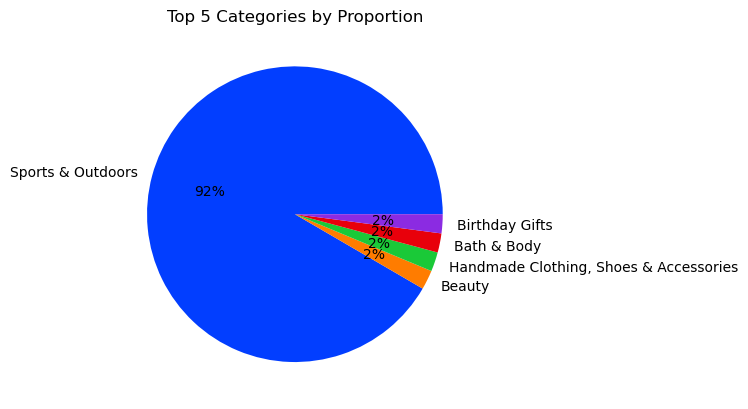

In [20]:
palette_color = sns.color_palette('bright')
plt.pie(top5_category_pro['proportion'], labels=top5_category_pro['category'], colors=palette_color, autopct='%.0f%%')
plt.title('Top 5 Categories by Proportion')
plt.show()

# Part 2: Delving into Product Pricing

Calculate the mean, median, and mode for the price of products.

In [23]:
round(df.groupby('category')['price'].agg(['mean', 'median', 'count', 'max']),2).sort_values(by='mean', ascending=False)

,mean,median,count,max
category,,,,
Laptops,1087.99,1042.72,7248,12519.99
3D Printers,1018.04,319.00,248,12999.00
Desktop PCs,926.82,810.40,7395,77752.00
Home Office Furniture,622.14,96.97,2462,18169.83
Test & Measurement,559.38,94.77,259,9322.98
...,...,...,...,...
Bedding Accessories,8.84,7.09,205,44.99
Adapters,8.75,7.05,254,67.18
Signs & Plaques,8.28,6.99,5282,129.99


What's the average price point of products listed? How does this compare with the most common price point (mode)?
avergae price is larger than mode

In [123]:
average_price = df['price'].mean()
average_price

89.24380943923663

In [121]:
mode_price = df['price'].mode()
mode_price

0    9.99
Name: price, dtype: float64

### Measures of Dispersion:
Determine the variance, standard deviation, range, and interquartile range for product price

In [27]:
df.describe().T.round(0)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.0,816056.0,1.0,658922.0,1349029.0,2060686.0,2828593.0
stars,2443651.0,2.0,2.0,0.0,0.0,0.0,4.0,5.0
reviews,2443651.0,481.0,5944.0,0.0,0.0,0.0,59.0,1356658.0
price,2443651.0,89.0,346.0,0.0,10.0,19.0,46.0,100000.0
boughtinlastmonth,2443651.0,26.0,240.0,0.0,0.0,0.0,0.0,50000.0


In [28]:
print('variance is', round(df['price'].var()))

variance is 119445


In [29]:
print('standard_deviation is', round(df['price'].std()))

standard_deviation is 346


In [30]:
print('range', df['price'].max() - df['price'].min())

range 100000.0


In [31]:
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
IQR = q3 - q1
print('Inter Quartile Range is',IQR)

Inter Quartile Range is 36.0


How varied are the product prices? Are there any indicators of a significant spread in prices?
datapoints are on average 346 far from mean point of 89 

In [33]:
df['price'].skew()

27.492977566280338

### Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..

using different number of bins to find the balance.



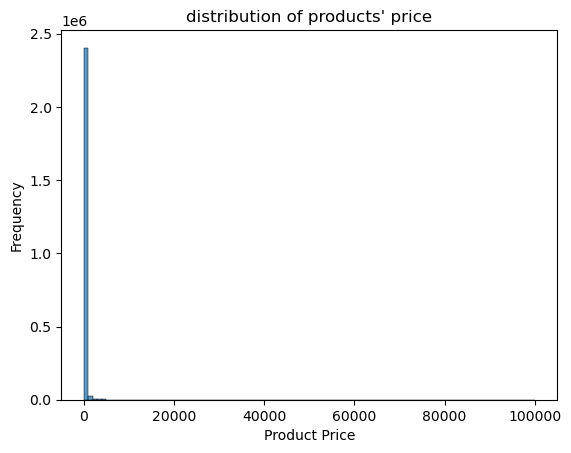

In [93]:
sns.histplot(df['price'], bins=100)
plt.title("distribution of products' price")
plt.xlabel("Product Price")
plt.ylabel("Frequency")
plt.show()

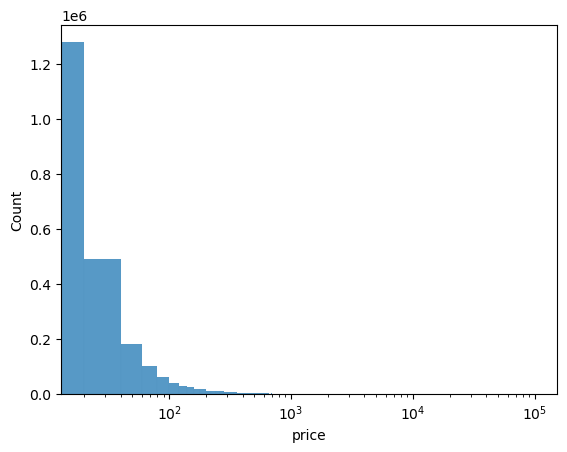

In [36]:
#As the histogram above doesnt show the right tail of price the logarithmic is used to better visulize the price distribution. 
sns.histplot(df.price, bins=5000)
plt.xscale('log')  
plt.show()

Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.
Yes

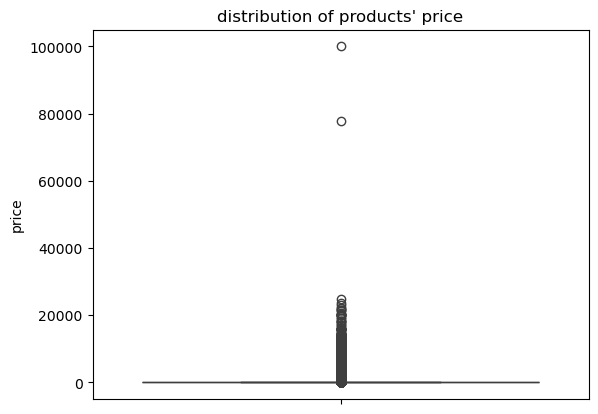

In [38]:
sns.boxplot(data=df['price'])
plt.title("distribution of products' price")
plt.show()

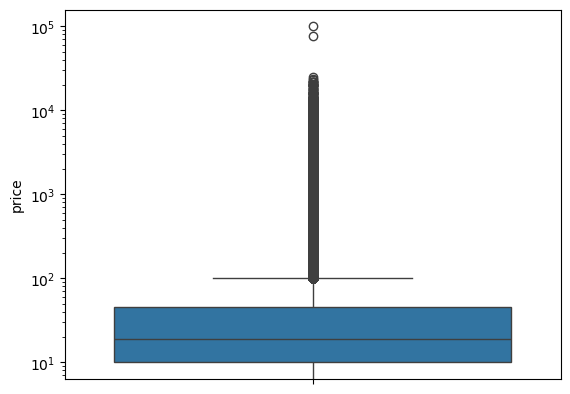

In [95]:
sns.boxplot(data=df.price)
plt.yscale('log')  
plt.show()
#box plot illustrate large amount of outliers for price

Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend? 

Majority of products recieved 0 star and the upper quartile 4 rating which impacted the average star rating to be 2.  

### Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

Star rating is far from mean by 2 standard deviation, while variance and IQR are high. This indicates the high dispersion between data. 

In [43]:
df.describe().T.round(0)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.0,816056.0,1.0,658922.0,1349029.0,2060686.0,2828593.0
stars,2443651.0,2.0,2.0,0.0,0.0,0.0,4.0,5.0
reviews,2443651.0,481.0,5944.0,0.0,0.0,0.0,59.0,1356658.0
price,2443651.0,89.0,346.0,0.0,10.0,19.0,46.0,100000.0
boughtinlastmonth,2443651.0,26.0,240.0,0.0,0.0,0.0,0.0,50000.0


In [41]:
#star rating per category of products
round(df.groupby('category')['stars'].agg(['mean', 'median','max']),2).sort_values(by='mean', ascending=False)

,mean,median,max
category,,,
Luxury Food & Drink,4.55,4.6,5.0
Grocery,4.47,4.5,5.0
Laptop Accessories,4.45,4.6,5.0
Health & Personal Care,4.44,4.5,5.0
Arts & Crafts,4.43,4.5,5.0
...,...,...,...
Motorbike Instruments,0.17,0.0,5.0
3D Printing & Scanning,0.15,0.0,5.0
"Motorbike Handlebars, Controls & Grips",0.13,0.0,5.0


In [116]:
print('Mode is', round(df['stars'].mode()))

Mode is 0    0.0
Name: stars, dtype: float64


In [44]:
print('variance is', round(df['stars'].var()))

variance is 5


In [45]:
print('standard deviation is', round(df['stars'].std()))

standard deviation is 2


In [46]:
print('range', df['stars'].max() - df['stars'].min())

range 5.0


In [47]:
q1 = df['stars'].quantile(0.25)
q3 = df['stars'].quantile(0.75)
IQR_star = q3 - q1
print('Inter Quartile Range is',IQR_star)

Inter Quartile Range is 4.4


## Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

In [49]:
df['stars'].skew()

0.08120735761080985

In [50]:
df['stars'].kurtosis()

-1.9260061280432985

Positive skew: data is positively skewed, with long term on the right and most of data is lean toward the lower end
Negative kurtosis: distribution of data is flatter, less data around a mean value and fewer outliers

## Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
most of product recieved zero star rating and otherhand on the right side of the histogram shows most of products has star rating of 4-5

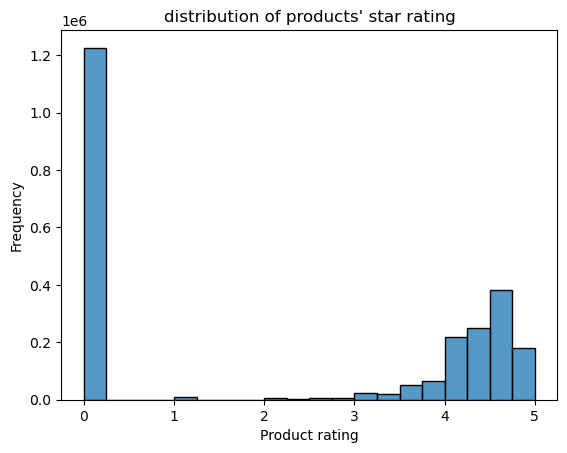

In [53]:
sns.histplot(df['stars'], bins=20)
plt.title("distribution of products' star rating")
plt.xlabel("Product rating")
plt.ylabel("Frequency")
plt.show()